# День 08. Упражнение 01
# Бинарный классификатор. SVM. Дерево решений

## 0. Импорты

In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

## 1. Предобработка и визуализация логистической регрессии

Прочитай файл am_pm.csv в DataFrame из предыдущего упражнения.

In [162]:
df = pd.read_csv("../data/am_pm.csv")
df.head(3)

,date,am,pm,target,predict
0,2020-04-17,21,2,working_day,weekend
1,2020-04-18,1,68,weekend,working_day
2,2020-04-19,18,15,weekend,working_day


1. Построй график, где по оси x — am, по оси y — pm, точки — это дни, цвет зависит от целевой переменной.

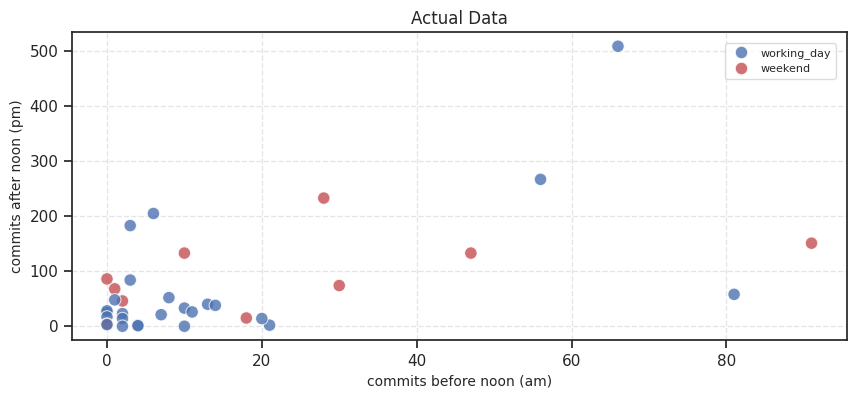

In [ ]:
def draw_plot(
    df_name, column, title_name, am_line=None, pm_line=None, boundary_mesh=None
):
    plt.figure(figsize=(10, 4))

    if boundary_mesh is not None:
        xx, yy, Z = boundary_mesh
        plt.contour(
            xx, yy, Z, levels=[0.5], colors="green", linestyles="-.", linewidths=2
        )

    sns.scatterplot(
        data=df_name,
        x="am",
        y="pm",
        hue=column,
        palette={"working_day": "b", "weekend": "r"},
        alpha=0.8,
        s=80,
    )
    if am_line is not None and pm_line is not None:
        plt.plot(
            am_line,
            pm_line,
            color="green",
            linestyle="-.",
            linewidth=2,
            label="Decision Boundary",
        )

    plt.xlabel("commits before noon (am)", fontsize=10)
    plt.ylabel("commits after noon (pm)", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.title(title_name)
    plt.legend(
        fontsize=8,
        loc="upper right",
        borderaxespad=1,
        frameon=True,
        facecolor="white",
        edgecolor="lightgray",
    )
    plt.show()


draw_plot(df, "target", "Actual Data", am_line=None, pm_line=None)

2. Добавь на график границу решений логистической регрессии.

In [ ]:
X = df[["am", "pm"]]
y = (df["target"] == "weekend").astype(int)
model = LogisticRegression(random_state=21, fit_intercept=False)
model.fit(X, y)
w1, w2 = model.coef_[0]
print(w1, w2)

0.000386526615277099 -0.0029806573907424157


In [ ]:
am_line = np.linspace(0, df["am"].max(), 100)
pm_line = -(w1 / w2) * am_line

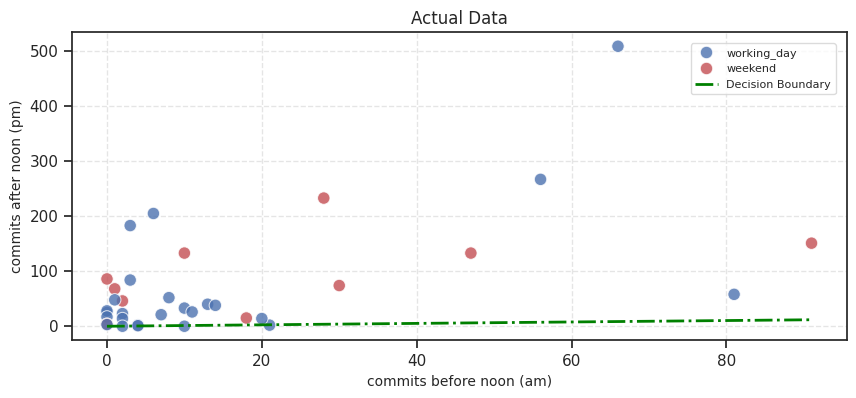

In [166]:
draw_plot(df, "target", "Actual Data", am_line=am_line, pm_line=pm_line)

3. Построй тот же график (с границей), но на этот раз цвет должен зависеть от предсказаний.
Теперь тебе должно быть понятно, как работает логистическая регрессия.
Да, модель провела разграничительную линию и все точки, которые оказались выше она отнесла к working_day (покрасила в синий), а все что под ней или на ней к weekend (красный).

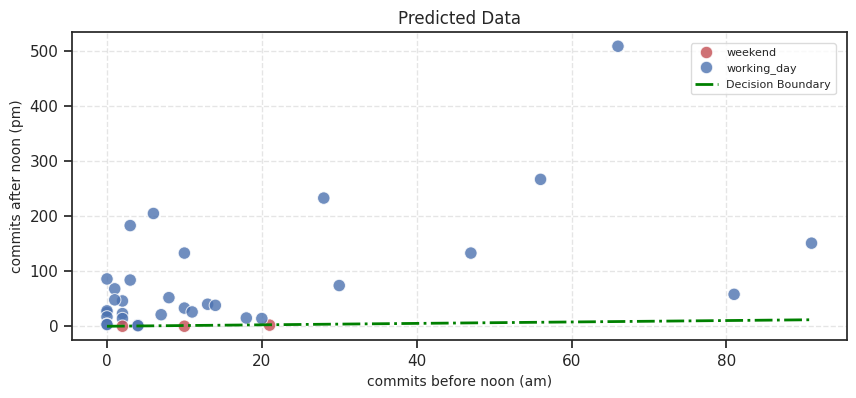

In [167]:
draw_plot(df, "predict", "Predicted Data", am_line=am_line, pm_line=pm_line)

## 2. Стандартизация и логистическая регрессия

Линейные модели чувствительны к масштабу переменных. Масштабирование признаков помогает модели проще находить оптимальное решение.

1. Применись StandardScaler к X и обучи логистическую регрессию снова с теми же параметрами.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
df_scaled = pd.DataFrame(X_scaled, columns=["am", "pm"])
df_scaled["target"] = df["target"]

In [ ]:
model_scaled = LogisticRegression(random_state=21, fit_intercept=False)
model_scaled.fit(X_scaled, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",21
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mult

In [ ]:
y_pred_scaled = model_scaled.predict(X_scaled)
df_scaled["predict"] = np.where(y_pred_scaled == 1, "weekend", "working_day")

2. Вычисли accuracy для новой модели. Стала ли она лучше наивного классификатора, предсказывающего самый частый класс?

In [ ]:
new_accuracy = accuracy_score(y, y_pred_scaled)
print(new_accuracy)

0.7428571428571429


ответ на вопрос: naive_accuracy из ex00 была = 0.7142857142857143, так что да, accuracy новой модели выше.

3. Построй описанные выше графики, но уже для новой модели.

In [ ]:
w1, w2 = model_scaled.coef_[0]
am_line_scaled = np.linspace(df_scaled["am"].min(), df_scaled["am"].max(), 100)
pm_line_scaled = -(w1 / w2) * am_line_scaled

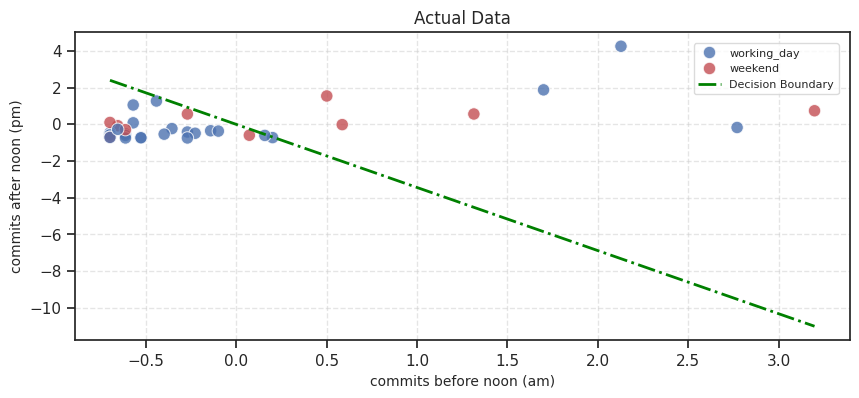

In [174]:
draw_plot(
    df_scaled, "target", "Actual Data", am_line=am_line_scaled, pm_line=pm_line_scaled
)

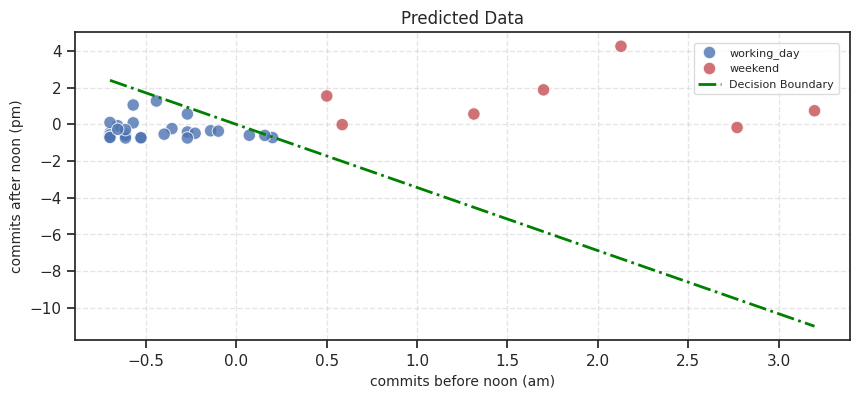

In [175]:
draw_plot(
    df_scaled,
    "predict",
    "Predicted Data",
    am_line=am_line_scaled,
    pm_line=pm_line_scaled,
)

## 3. SVM

1. Применись модель SVC к масштабированному DataFrame с параметрами probability=True, random_state=21.
2. Вычисли accuracy.
3. Попробуй разные ядра и найди то, которое дает наилучшую точность.
4. Построй оба графика снова с границей решений, чтобы увидеть, как работает этот алгоритм.

In [176]:
df_scaled.head(3)

,am,pm,target,predict
0,0.200690,-0.719904,working_day,working_day
1,-0.655914,-0.071822,weekend,working_day
2,0.072199,-0.592251,weekend,working_day


In [ ]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
accuracy_history = {}
trained_models = {}

for k in kernels:
    model_svc = SVC(kernel=k, probability=True, random_state=21)
    model_svc.fit(X_scaled, y)
    y_pred_svc = model_svc.predict(X_scaled)
    acc = accuracy_score(y, y_pred_svc)
    accuracy_history[k] = acc
    trained_models[k] = model_svc

print(accuracy_history)
highest_accuracy = max(accuracy_history.values())
best_kernels = [k for k, v in accuracy_history.items() if v == highest_accuracy]
print(f"Наилучшая точность для модели SVC: {highest_accuracy}")
print(f"Ядро с такой точностью: {', '.join(best_kernels)}")

{'linear': 0.7142857142857143, 'poly': 0.7428571428571429, 'rbf': 0.7428571428571429, 'sigmoid': 0.6857142857142857}
Наилучшая точность для модели SVC: 0.7428571428571429
Ядро с такой точностью: poly, rbf


In [178]:
final_svc = trained_models["rbf"]
final_svc

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [179]:
df_scaled["predict_svc"] = np.where(
    final_svc.predict(X_scaled) == 1, "weekend", "working_day"
)
df_scaled.head(3)

,am,pm,target,predict,predict_svc
0,0.200690,-0.719904,working_day,working_day,working_day
1,-0.655914,-0.071822,weekend,working_day,working_day
2,0.072199,-0.592251,weekend,working_day,working_day


In [ ]:
x_min, x_max = df_scaled["am"].min() - 0.5, df_scaled["am"].max() + 0.5
y_min, y_max = df_scaled["pm"].min() - 0.5, df_scaled["pm"].max() + 0.5

In [ ]:
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

In [ ]:
Z_svc = final_svc.predict(np.c_[xx.ravel(), yy.ravel()])
Z_svc = Z_svc.reshape(xx.shape)
svc_mesh_data = (xx, yy, Z_svc)

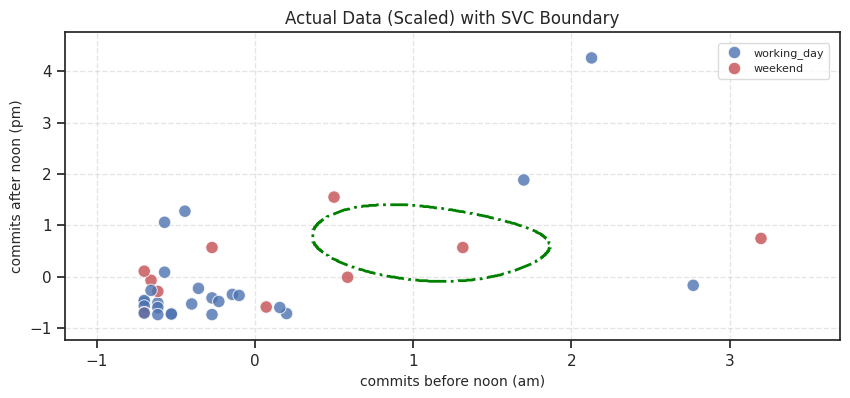

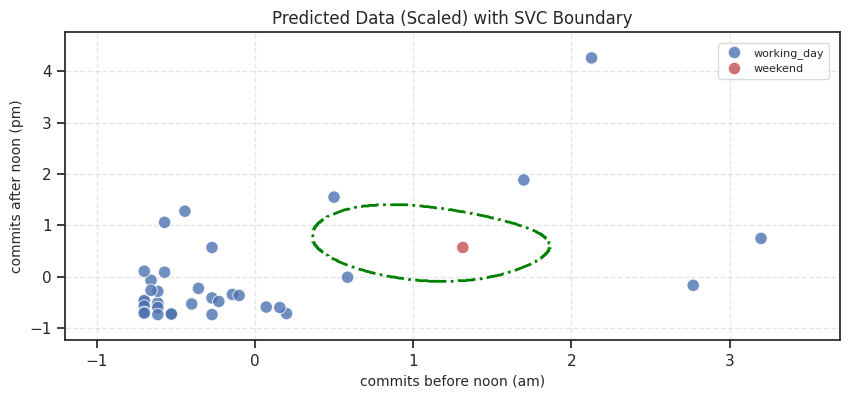

In [ ]:
draw_plot(
    df_scaled,
    "target",
    "Actual Data (Scaled) with SVC Boundary",
    boundary_mesh=svc_mesh_data,
)

draw_plot(
    df_scaled,
    "predict_svc",
    "Predicted Data (Scaled) with SVC Boundary",
    boundary_mesh=svc_mesh_data,
)

## 4. Дерево решений

1. Применись DecisionTreeClassifier к масштабированному DataFrame с параметрами max_depth=4, random_state=42.

In [184]:
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_scaled, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

2. Вычисли accuracy.

In [185]:
y_predDT = dt_model.predict(X_scaled)
acc = accuracy_score(y, y_predDT)
acc

0.9428571428571428

3. Попробуй разные значения max_depth.

In [ ]:
for depth in [i for i in range(1, 7)]:
    temp_modelDT = DecisionTreeClassifier(max_depth=depth, random_state=42)
    temp_modelDT.fit(X_scaled, y)
    score = accuracy_score(y, temp_modelDT.predict(X_scaled))
    print(f"Accuracy для max_depth={depth}: {score}")

Accuracy для max_depth=1: 0.7714285714285715
Accuracy для max_depth=2: 0.8571428571428571
Accuracy для max_depth=3: 0.8857142857142857
Accuracy для max_depth=4: 0.9428571428571428
Accuracy для max_depth=5: 0.9714285714285714
Accuracy для max_depth=6: 1.0


4. Построй оба графика снова с границей решений, чтобы увидеть, как работает этот алгоритм.

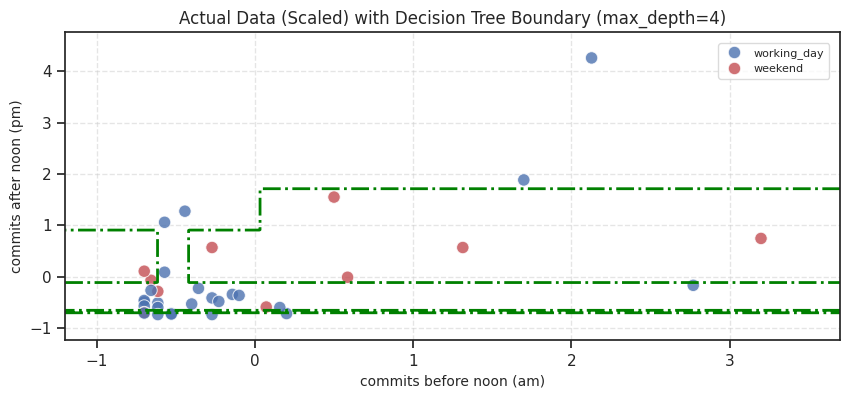

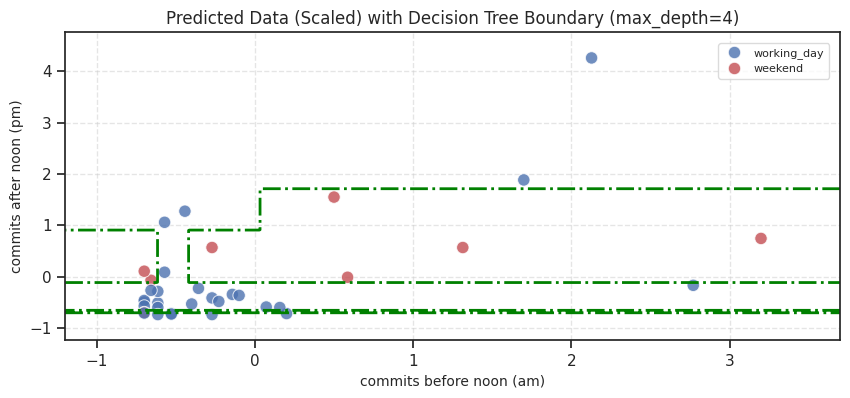

In [ ]:
Z_dt = dt_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

draw_plot(
    df_scaled,
    "target",
    "Actual Data (Scaled) with Decision Tree Boundary (max_depth=4)",
    boundary_mesh=(xx, yy, Z_dt),
)

df_scaled["predict_dt"] = np.where(y_predDT == 1, "weekend", "working_day")

draw_plot(
    df_scaled,
    "predict_dt",
    "Predicted Data (Scaled) with Decision Tree Boundary (max_depth=4)",
    boundary_mesh=(xx, yy, Z_dt),
)

5. С помощью метода .plot_tree() визуализируй само дерево решений. Это еще один способ понять, как работает алгоритм.

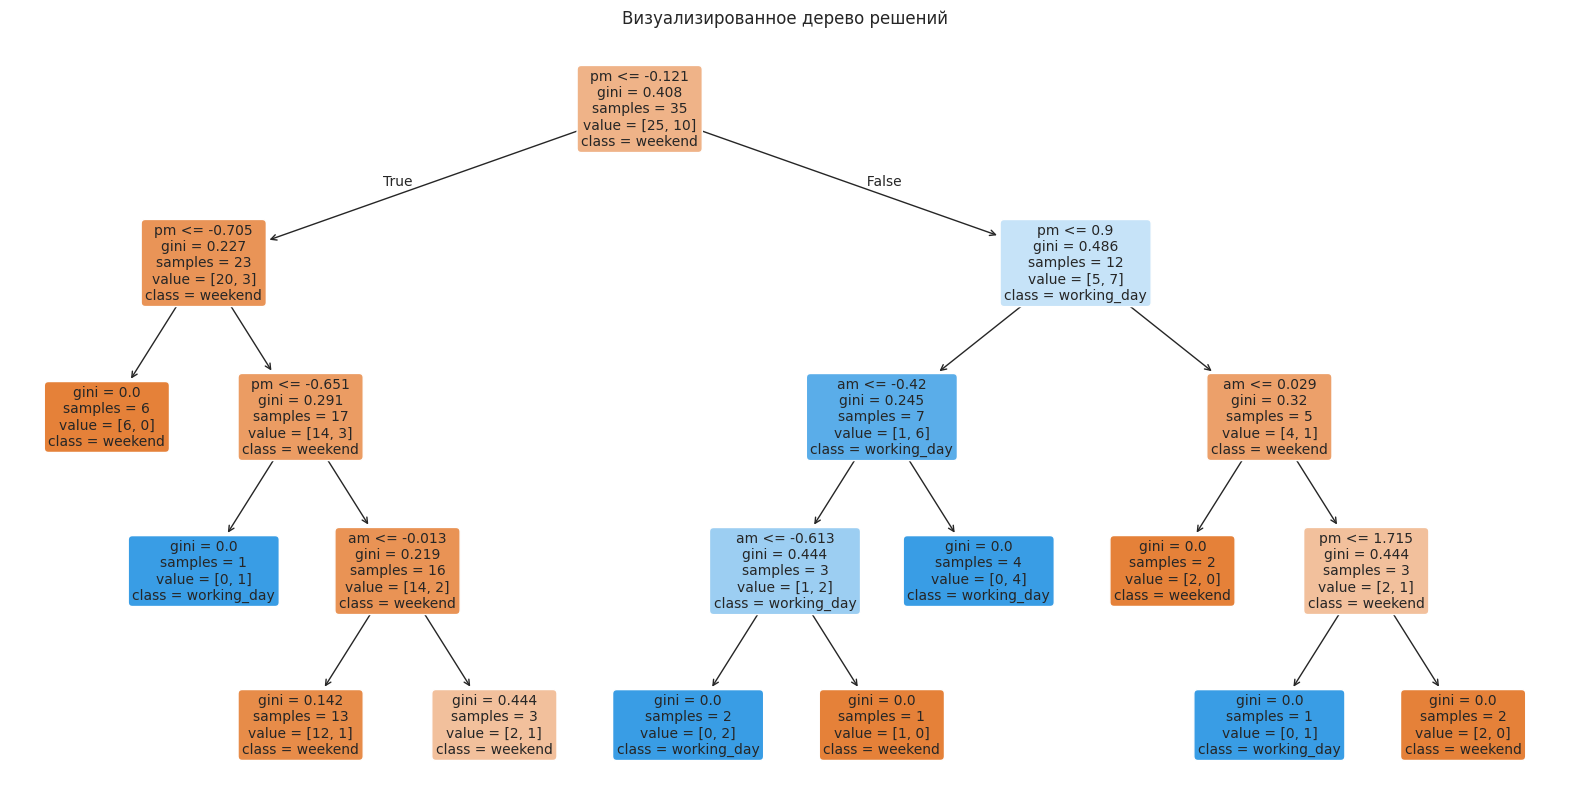

In [188]:
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    filled=True,
    feature_names=["am", "pm"],
    class_names=["weekend", "working_day"],
    rounded=True,
    fontsize=10,
)
plt.title("Визуализированное дерево решений")
plt.show()

6. Сколько листьев на визуализированном дереве обозначают рабочие дни? Напиши ответ в markdown-ячейке в конце раздела.

4